# 01 — Data Audit

Load PG-19 metadata, audit it (shape, types, missing values, duplicates, target distribution, outliers), define the publication-period buckets and draw a stratified sample of books.

## Setup

In [1]:
import sys
from pathlib import Path

sys.path.append(str(Path.cwd().parent))

import pandas as pd
import matplotlib.pyplot as plt

from src import config

## Load metadata

`metadata.csv` has one row per book: id, title, publication year and Gutenberg URL.
The file has no header row, so the column names are set by hand.

In [2]:
meta = pd.read_csv(
    config.METADATA_PATH,
    header=None,
    names=["id", "title", "publication_date", "url"],
)
meta.head()

,id,title,publication_date,url
0,10005,A Voyage to the Moon by George Tucker,1828,http://www.gutenberg.org/ebooks/10005
1,10006,La Fiammetta by Giovanni Boccaccio,1907,http://www.gutenberg.org/ebooks/10006
2,1001,Divine Comedy Inferno by Dante Alighieri,1882,http://www.gutenberg.org/ebooks/1001
3,10021,Tenterhooks by Ada Leverson,1912,http://www.gutenberg.org/ebooks/10021
4,10024,Beneath the Banner by F. J. Cross,1895,http://www.gutenberg.org/ebooks/10024


## Audit: shape, types, missing values, duplicates

In [3]:
print(meta.shape)
print(meta.dtypes)
print(meta.isna().sum())
print("Duplicate ids:", meta["id"].duplicated().sum())
print("Duplicate titles:", meta["title"].duplicated().sum())
dupes = meta[meta["title"].duplicated(keep=False)].sort_values("title")
display(dupes.head(12))
meta["publication_date"].describe()

(28752, 4)
id                  int64
title                 str
publication_date    int64
url                   str
dtype: object
id                  0
title               0
publication_date    0
url                 0
dtype: int64
Duplicate ids: 0
Duplicate titles: 558


,id,title,publication_date,url
9408,46507,A Catalogue of Books and Announcements of Meth...,1897,http://www.gutenberg.org/ebooks/46507
17935,46506,A Catalogue of Books and Announcements of Meth...,1902,http://www.gutenberg.org/ebooks/46506
1283,25493,A Cathedral Courtship by Kate Douglas Wiggin,1897,http://www.gutenberg.org/ebooks/25493
409,1551,A Cathedral Courtship by Kate Douglas Wiggin,1894,http://www.gutenberg.org/ebooks/1551
1318,25609,A Child's Garden of Verses by Robert Louis Ste...,1905,http://www.gutenberg.org/ebooks/25609
1319,25610,A Child's Garden of Verses by Robert Louis Ste...,1895,http://www.gutenberg.org/ebooks/25610
27115,136,A Child's Garden of Verses by Robert Louis Ste...,1885,http://www.gutenberg.org/ebooks/136
24203,25611,A Child's Garden of Verses by Robert Louis Ste...,1885,http://www.gutenberg.org/ebooks/25611
1317,25608,A Child's Garden of Verses by Robert Louis Ste...,1908,http://www.gutenberg.org/ebooks/25608
24930,10895,A Compilation of the Messages and Papers of th...,1897,http://www.gutenberg.org/ebooks/10895


count    28752.000000
mean      1883.640477
std         44.429790
min       1483.000000
25%       1876.000000
50%       1897.000000
75%       1909.000000
max       1918.000000
Name: publication_date, dtype: float64

**Findings:**
- 28,752 books and 4 columns, with the expected types (id and year are integers).
- No missing values and no duplicate ids.
- 558 titles appear more than once. These are usually different volumes or editions of the same work,
  sometimes with different dates (e.g. *A Child's Garden of Verses* appears as 1885, 1895, 1905 and 1908).
  This is handled when sampling, below.
- Publication years range from 1483 to 1918. Half of all books are from 1897 or later.

**Outliers:**
- **Very early years:** the earliest book is from 1483. These are genuine early printed books, not errors,
  so they are kept (they fall into the pre-1750 period).
- **Wrong dates:** some books are dated centuries too early, e.g. *U.S. Copyright Renewals 1959* is dated 1780.
  Known cases are removed below, and notebook 02 checks every sampled book for this.
- **Book length:** books range from 442 to 818,001 words (measured in notebook 02). Very short books are removed and
  every book is cut to a 5,000-word excerpt there, so length can't affect the model.

## Publication-date distribution and period buckets

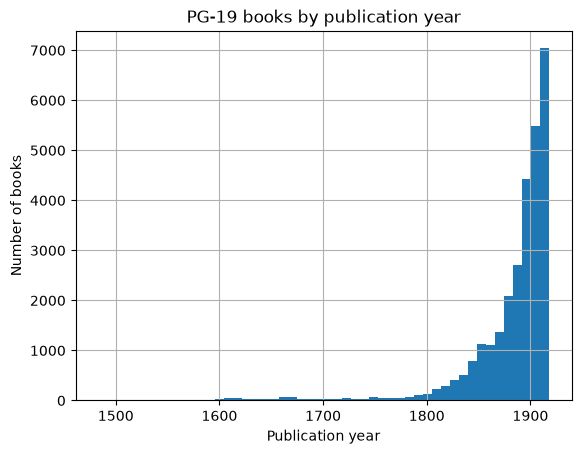

In [4]:
meta["publication_date"].hist(bins=50)
plt.xlabel("Publication year")
plt.ylabel("Number of books")
plt.title("PG-19 books by publication year")
plt.savefig(config.FIGURES_DIR / "year_histogram.png", bbox_inches="tight")
plt.show()

The histogram shows most books are from the second half of the 19th century onwards.
Each year is converted into one of five periods. The period is the label the model will learn to predict.

In [5]:
bins = [0, 1749, 1799, 1849, 1899, 1918]
labels = ["pre-1750", "1750-1799", "1800-1849", "1850-1899", "1900-1918"]
meta["period"] = pd.cut(meta["publication_date"], bins=bins, labels=labels)

In [6]:
meta["period"].value_counts().sort_index()

period
pre-1750       698
1750-1799      396
1800-1849     2405
1850-1899    12109
1900-1918    13144
Name: count, dtype: int64

The periods are very unbalanced: from 396 books (1750–1799) to 13,144 (1900–1918).
If we trained on all of them, a model could score well by mostly guessing the recent periods.
So we sample the **same number of books from each period** instead.

## Checking the publication dates

Some PG-19 dates may be when an edition was published, not when the book was written.
Spot-check with well-known books whose original dates are known
(Pride and Prejudice 1813, Frankenstein 1818, Oliver Twist 1838).

In [7]:
meta[meta["title"].str.contains("Pride and Prejudice|Oliver Twist|Frankenstein")]

,id,title,publication_date,url,period
7959,42671,Pride and Prejudice by Jane Austen,1813,http://www.gutenberg.org/ebooks/42671,1800-1849
15309,47530,Oliver Twist Vol. II of 3 by Charles Dickens,1839,http://www.gutenberg.org/ebooks/47530,1800-1849
16377,47529,Oliver Twist Vol. I of 3 by Charles Dickens,1839,http://www.gutenberg.org/ebooks/47529,1800-1849
16484,47531,Oliver Twist Vol. III of 3 by Charles Dickens,1839,http://www.gutenberg.org/ebooks/47531,1800-1849
16698,46675,Oliver Twist Illustrated by Charles Dickens,1839,http://www.gutenberg.org/ebooks/46675,1800-1849
18617,41445,Frankenstein by Mary Shelley,1818,http://www.gutenberg.org/ebooks/41445,1800-1849
20058,42324,Frankenstein by Mary W. Shelley,1831,http://www.gutenberg.org/ebooks/42324,1800-1849
26748,1342,Pride and Prejudice by Jane Austen,1813,http://www.gutenberg.org/ebooks/1342,1800-1849
27403,84,Frankenstein by Mary Wollstonecraft (Godwin) S...,1818,http://www.gutenberg.org/ebooks/84,1800-1849
27503,730,Oliver Twist by Charles Dickens,1839,http://www.gutenberg.org/ebooks/730,1800-1849


The dates mostly match original publication: Pride and Prejudice 1813, Frankenstein 1818
(plus 1831, a real revised edition) and Oliver Twist 1839 (one year off).
However, some dates are clearly edition dates (e.g. *A Child's Garden of Verses*, written 1885, also dated 1905 and 1908),
and some later inspection found modern documents dated centuries too early. So the labels contain some noise.

This output also shows the same work appearing under different titles
("Oliver Twist", "Oliver Twist Vol. I of 3", "Oliver Twist Illustrated").

## Removing problem titles and duplicate works

Inspecting earlier draws of the sample found titles that should not be used:
- **Bibles:** several overlapping editions (e.g. a complete Bible and parts of the same Bible) would put the same text in the data more than once.
- **Modern documents with wrong dates:** e.g. *U.S. Copyright Renewals 1959* (dated 1780), *Conestoga Wagons in Braddock's Campaign 1755* (a 1950s paper, dated 1758), *A Birder's Guide to North Dakota* (dated 1843).
- **Non-English texts:** e.g. *Maldita Felicidade* (Portuguese), *Correspondance Diplomatique* (French).

These are removed by title before sampling.

In [8]:
bad = "Bible|Douay|Old Testament|New Testament|Copyright Renewals|Tonto National|Conestoga|Birder|Patent Medicines|Maldita|Correspondance"
meta = meta[~meta["title"].str.contains(bad, case=False)]

Many books are one volume or part of a larger work (e.g. nine different months of *The Diary of Samuel Pepys*,
several parts of *Don Quixote*). If several pieces of one work were sampled, the model could learn to recognise
that work's style instead of its period, and pieces could end up in both training and test data.

To prevent this, each book gets a short **work** name: the title is lower-cased, apostrophes are removed,
it is cut at words like "Vol", "Part", "No." or "by", and the first 4 words are kept.
So "The Diary of Samuel Pepys April 1667" and "...August 1668" both become "the diary of samuel".

In [9]:
meta["work"] = (
    meta["title"].str.lower()
    .str.replace("'", "")
    .str.split(r" vol| volume| part| no\. | number | v\. | by |;|\(|:|,", regex=True).str[0]
    .str.split().str[:4].str.join(" ")
)

Keep only one book per work: the one with the earliest date, as it is most likely closest to when the work was written.

In [10]:
unique_books = meta.sort_values("publication_date").drop_duplicates("work", keep="first")
print(unique_books["period"].value_counts().sort_index())

period
pre-1750       493
1750-1799      327
1800-1849     1644
1850-1899     9208
1900-1918    10964
Name: count, dtype: int64


Even after removing duplicates, the smallest period (1750–1799) still has 327 books, enough to sample 100 from each period.

## Stratified sample

Take 100 random books from each period (500 in total), so every period counts equally.
`random_state` makes the sample the same every time the notebook is run.
The sample is saved to `data/interim/sample.csv` for notebook 02.

In [11]:
sample = unique_books.groupby("period", observed=True).sample(n=100, random_state=config.RANDOM_STATE)
print("Most books from one work:", sample["work"].value_counts().max())
sample.to_csv(config.INTERIM_DIR / "sample.csv", index=False)

Most books from one work: 1


"Most books from one work: 1" confirms that no work appears twice in the sample.

In [12]:
(sample.sort_values("title")["title"].to_list())

["?op's Fables by ?op",
 'A Briefe and True Report of the New Found Land Of Virginia',
 'A Collection of Emblemes Ancient and Moderne by George Wither',
 'A Colonial Reformer Vol. 1 of 3 by Rolf Boldrewood',
 'A Complete Account of the Settlement at Port Jackson by Watkin Tench',
 'A Complete List of the S. & C. Series of Books by',
 'A Dialogue Between Dean Swift and Tho. Prior Esq. by Anonymous',
 'A Dialogue upon the Gardens by William Gilpin',
 'A Fluttered Dovecote by George Manville Fenn',
 'A History of Sarawak under Its Two White Rajahs 1839-1908',
 'A Jolly by Josh by Josh',
 "A Lady's Life in the Rocky Mountains by Isabella L. Bird",
 'A Learned Dissertation on Dumpling (1726) by Anonymous',
 'A Letter Addressed to the Abbe Raynal by Thomas Paine',
 'A Letter to Lord Robert Bertie by Anonymous',
 'A Letter to a Gentleman in the Country From His Friend in London',
 'A Little English Gallery by Louise Imogen Guiney',
 "A Man's World by Albert Edwards",
 'A New Century of Invent

The sampled titles were skimmed by hand. A few overlaps remain that the work name cannot catch,
because the titles are completely different: e.g. *The Complete Shakespeare's First Folio* contains
*The Winters Tale* and *Romeo and Juliet*, which are also sampled on their own.
Re-drawing the sample would just swap in other odd books, so this is handled in notebook 02 instead,
by keeping all books by the same author on the same side of the train/test split.

## Download the book texts

Each book's text is downloaded from the PG-19 storage bucket into `data/raw/books/`.
PG-19 stores books in `train/`, `validation/` or `test/` folders, so each folder is tried in turn.
Books already downloaded are skipped, so the cell can be re-run safely.

In [13]:
import requests
from tqdm import tqdm

BOOKS_DIR = config.RAW_DIR / "books"
BOOKS_DIR.mkdir(exist_ok=True)

def download_book(book_id):
    path = BOOKS_DIR / f"{book_id}.txt"
    if path.exists():                      # already downloaded, skip
        return True
    for folder in ["train", "validation", "test"]:
        url = f"{config.PG19_BASE_URL}/{folder}/{book_id}.txt"
        r = requests.get(url, timeout=60)
        if r.status_code == 200:
            path.write_bytes(r.content)
            return True
    return False                           # not found anywhere

results = [download_book(i) for i in tqdm(sample["id"])]
print("Downloaded:", sum(results), "of", len(results))

100%|██████████| 500/500 [00:00<00:00, 22686.87it/s]

Downloaded: 500 of 500


All 500 sampled books were downloaded.

## Summary and limitations

- 28,752 books in PG-19; no missing values or duplicate ids.
- Five periods, very unbalanced in the full data, so 100 books were sampled from each (500 total).
- Removed before sampling: duplicate Bibles, modern documents with wrong dates, non-English texts,
  and all but one volume/part of each work.

**Limitations:**
- Some publication dates are wrong (edition dates, or modern documents dated far too early), so some labels are noisy.
- Some books are translations, so their English reflects the translator's time, not the original author's
  (e.g. Don Quixote, dated 1616–1620, is in 19th-century English).
- Different editions of the same work can have different titles, and anthologies can overlap with single works
  (e.g. the Shakespeare First Folio), so some duplicate text may remain.